# Pale Blue Flame: what NASA's fire data looks like
Data: NASA Physical Sciences Informatics (PSI), Combustion Science. Open API, no login.

## 1. What exists
NASA keeps its fire experiments in the PSI database. This lists every **combustion** investigation: 24 of them. Most flew on the Space Station; a few (no name) are computer models, not experiments.

In [7]:
# Step 1: the list of NASA's fire (combustion) investigations, straight from the PSI API
import requests, pandas as pd, io, urllib.parse
API = "https://psi.nasa.gov/geode-py/ws"
hits = requests.get(f"{API}/repo/search", params={"size": 500, "ffield": "Research Area",
                    "fvalue": "combustion science"}).json()["hits"]["hits"]
inv = pd.DataFrame([{"id": h["_source"]["Accession"], "name": h["_source"]["Acronym"],
                     "where": h["_source"]["Flight Platform"], "topic": h["_source"]["SubResearch Area"],
                     "title": h["_source"]["Title"]} for h in hits]).sort_values("id")
print(len(inv), "investigations")
inv


24 investigations


,id,name,where,topic,title
21,PSI-10,ACME/Flame Design,International Space Station (ISS),Flames of Gaseous Fuels,Advanced Combustion via Microgravity Experimen...
9,PSI-100,SAFFIRE-III,International Space Station (ISS),Spacecraft Fire Safety,Spacecraft Fire Experiment-III
13,PSI-101,SAME-R,International Space Station (ISS),Spacecraft Fire Safety,Smoke Aerosol Measurement Experiment-Reflight
11,PSI-102,SAME,International Space Station (ISS),Spacecraft Fire Safety,Smoke and Aerosol Measurement Experiment
4,PSI-106,SLICE,International Space Station (ISS),,Structure and Liftoff In Combustion Experiment
17,PSI-107,SPICE,International Space Station (ISS),Fire Safety,Smoke Point In Co-flow Experiment
7,PSI-115,,Not Applicable,"Smoke Aerosol, Combustion Simulation",Utilization of the Smoke Aerosol Measurement E...
6,PSI-117,,,Droplet,Effect of External Thermo-Convective Perturbat...
0,PSI-142,,Not Applicable,Spacecraft Fire Safety,Quantitative Studies of Cool Flame Transitions...
12,PSI-159,ACME CFI-G,International Space Station (ISS),Flames of Gaseous Fuels,Advanced Combustion via Microgravity Experimen...


## 2. The test tables
Each experiment has a **test table**: one row per fire it lit, with the conditions (material, oxygen, airflow, ...). This downloads all of them. `records`, `tables` and `all_tables` are used by every step below.

In [8]:
# Step 2: each investigation has one or more "test tables": one row per fire test. Download them all.
# The cleaning notebook copies this cell and the one above unchanged.
def record(acc):
    return requests.get(f"{API}/repo/investigations/{acc}").json()

def download(acc, file_name, version):
    url = requests.get(f"{API}/studies/{acc}/download",
                       params={"file": file_name, "version": version, "redirect": "false"}).text.strip()
    return requests.get(url).content

def read_csv(raw):
    return pd.read_csv(io.StringIO(raw.decode("utf-8", "ignore").lstrip("﻿")))

records, tables, all_tables = {}, {}, {}
for acc in inv["id"]:
    rec = records[acc] = record(acc)
    ts = [read_csv(download(acc, e["file_name"], e["version"])) for e in rec.get("experimentalTable", [])]
    if ts:
        tables[acc], all_tables[acc] = ts[0], ts
summary = pd.DataFrame([{"id": a, "name": inv.set_index("id").loc[a, "name"], "tables": len(all_tables[a]),
                         "tests": sum(len(t) for t in all_tables[a]), "columns": len(tables[a].columns)}
                        for a in tables]).sort_values("tests", ascending=False)
print(len(tables), "of", len(inv), "have a test table;", summary.tests.sum(), "test rows in total")
summary


20 of 24 have a test table; 2870 test rows in total


,id,name,tables,tests,columns
7,PSI-159,ACME CFI-G,2,1194,18
5,PSI-107,SPICE,1,469,9
0,PSI-10,ACME/Flame Design,2,327,15
17,PSI-69,FLEX,1,274,15
12,PSI-25,BASS-II,1,129,17
13,PSI-26,BASS,1,122,6
2,PSI-101,SAME-R,1,109,10
14,PSI-39,CFI,1,87,10
10,PSI-22,ACME E-FIELD Flames,1,32,10
9,PSI-21,ACME CLD Flame,1,32,8


## 3. Every table is different
Same idea, different column names, different units, different detail. Compare six of them.

In [9]:
# Step 3: what do the columns look like? Every experiment names them differently.
for a in ["PSI-25", "PSI-26", "PSI-98", "PSI-99", "PSI-102", "PSI-69"]:
    print(f"{a} {inv.set_index('id').loc[a, 'name']:12} ->", list(tables[a].columns)[:12])


PSI-25 BASS-II      -> ['PI', 'Test #', 'Date', 'GMT', 'Sample #', 'Fuel Sample Material', 'Flow restrictor', 'Fan display', 'Air display', 'Radiometer gain   (1000   250   50   10)', 'Total Frames Shot', 'Calibrated  initial O2 % by vol ']
PSI-26 BASS         -> ['Date', 'GMT', 'As Run Test #', 'Test #', 'Sample #', 'Fuel Sample Material']
PSI-98 SAFFIRE-I    -> ['Sample Number ', 'Material', 'Sample Thickness (cm)', 'Sample Length (cm)', 'Sample Width (cm)', 'Air Flow (cm/s)', 'Percent O2', 'Ignition Power (W)', 'Ignition Time (s)', 'Burn Time (s)', 'Flow Direction ', 'Camera 1']
PSI-99 SAFFIRE-II   -> ['Sample Number', 'Material', 'Samle Thickness ', 'Sample Length ', 'Sample Width (cm)', 'Air Flow (cm/s)', 'Percent O2 (Note 1)', 'Ignition Power (W)', 'Ignition Time (s)', 'Burn Time (s)', 'Flow Direction', '?-g Burn Length']
PSI-102 SAME         -> ['Sample #', 'Sample Material  ', 'Air Flow (cm/s)', 'Weight loss rate (mg/min)', 'Aging Duration (minutes)']
PSI-69 FLEX         -> ['F

## 4. BASS-II: the biggest material test table
129 burns of acrylic (PMMA) and cotton-fiberglass in Space Station air. Look at the **Fuel Sample Material** column: free text.

In [10]:
# Step 4: the material burns (the data our idea needs). BASS-II is the biggest one.
bass2 = tables["PSI-25"]
bass2.head(10)


,PI,Test #,Date,GMT,Sample #,Fuel Sample Material,Flow restrictor,Fan display,Air display,Radiometer gain (1000 250 50 10),Total Frames Shot,Calibrated initial O2 % by vol,Calibrated final O2 % by vol,Initial CO2 % by vol,Final CO2 % by vol,Initial CO (ppm),Final CO (ppm)
0,Bhattacharjee,B1,2/19/2014,50,147,100 micron PMMA film 2 cm wide,2,62,5,50,57,22.2,22.2,0.44,0.44,0,6
1,Bhattacharjee,B2,2/19/2014,50,155,200 micron PMMA film 2 cm wide,2,62,5,50,none,22.2,1.6,0.44,NaN,6,NaN
2,Bhattacharjee,B3,2/19/2014,50,148,100 micron film 2 cm wide,2,47,2,50,253,22.2,21.8,0.43,0.49,12,19
3,Bhattacharjee,B4,2/19/2014,50,159,300 micron PMMA film 2 cm wide,2,61,5,50,137,22.2,22.2,0.44,0.51,-1,10
4,Bhattacharjee,B5,2/19/2014,50,156,200 micron 2 cm wide,2,59,5,50,206,22.2,21.9,0.43,0.43,0,12
5,Bhattacharjee,B6,7/7/2014,188,153m,2 cm 0.1 mm PMMA film,2,0.9 1.3 2.75,3 5 approaching 10,10,80,21.0,20.9,0.33,0.41,0,0.3
6,Bhattacharjee,B7,2/19/2014,50,161,400 micron film 2 cm wide,2,47,2,50,84,22.2,22.1,0.45,0.51,1,17
7,Bhattacharjee,B8,7/7/2014,188,157m,2 cm 0.2 mm PMMA film,0,1.4 incr to 10.0,10 max,10,226,21.0,20.5,0.33,0.58,0,131
8,Bhattacharjee,B9,7/7/2014,188,154m,2 cm 0.1 mm PMMA film,2,0.6 0.35,2 <1,10,45,21.0,20.9,0.33,0.35,0,10
9,Bhattacharjee,B10,7/7/2014,188,173m,1 cm 0.2 mm PMMA film,2,1.7 (52) 1.25 0.9 0.6 0.4 0.35,5 4 3 2 1,10,123,21.0,20.8,0.33,0.44,0,23


## 5. Saffire-II: burned on a cargo ship after it left the Space Station
Only 15 rows, but cleaner, and it has burn lengths (a result). Scroll to the bottom: the footnotes are stored as rows.

In [11]:
# Step 5: Saffire-II, burned on a cargo spacecraft: a cleaner table, but only 15 rows
tables["PSI-99"]


,Sample Number,Material,Samle Thickness,Sample Length,Sample Width (cm),Air Flow (cm/s),Percent O2 (Note 1),Ignition Power (W),Ignition Time (s),Burn Time (s),Flow Direction,?-g Burn Length,?-g Spread Length,1-g Burn Length,1-g Spread Rate,Camera 1,Camera 2
0,2-1,Silicone,0.27 mm,29 cm,5 cm,20 cm/s,~ 21.5,80 W,9.2 s,Insignificant,Concurrent,~ 0,NaN,Complete,Acceleratory,S1C1,S1C2
1,2-2,Silicone,0.61 mm,29 cm,5 cm,20 cm/s,~ 22.1,80 W,9.2 s,Insignificant,Concurrent,~ 0,NaN,7.6 cm,1.2 mm/s,NaN,S2C2
2,2-3,Silicone,1.03 mm,29 cm,5 cm,20 cm/s,~ 22.1,80 W,9.2 s,Insignificant,Concurrent,~ 0,NaN,~ 0,NaN,NaN,S3C2
3,2-4,Silicone,037 mm,29 cm,5 cm,20 cm/s,~ 22.1,80 W,9.2 s,Insignificant,Opposed,~ 0,NaN,Complete,0.6 mm/s,S4C1,S4C1
4,2-5,Cotton-Fiberglass (SIBAL),037 mm,29 cm,5 cm,20 cm/s,~ 22.1,80 W,9.2 s,145 s,Concurrent,29 cm,2.1 mm/s,Complete,Acceleratory,S5C1,S5C2
5,2-6,NaN,037 mm,29 cm,5 cm,20 cm/s,~ 22.1,80 W,9.2 s,115 s,Concurrent,29 cm,2.6 mm/s,Complete,Acceleratory,S6C1,S56C2
6,2-7,PMMA & Nomex,0.85 and 0.37 mm,5 and 24 cm,5 cm,20 cm/s,~ 22.1,80 W,9.2 s,140 s,Concurrent,5 cm & 0 (note 2),n/a (Nomex),~ 0 (Nomex),n/a (Nomex),S7C1,NaN
7,2-8,PMMA,See Fig. 5,29 cm,5 cm,20 cm/s,22.1 to 22.0,97 W,30 s,600 s,Concurrent,~ 10 cm (note 3),Note 4,Complete,Acceleratory,S8C1,NaN
8,2-9,NaN,1 cm,29 cm,5 cm,20 cm/s,22.0 to 21.9,97 W,30 s,900 s,Concurrent,~ 10 cm (note 4),Note 4,Complete,Acceleratory,S9C1,NaN
9,F1C1/F1C2,Pre-test flow visulation data for sample 2-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. The picture
Left: most tests are gas flames and droplets (grey); the material burns we need are green. Right: every BASS-II test was at 14-22% oxygen. A Moon base would be ~34%: **nothing was tested there**. That gap is our project.

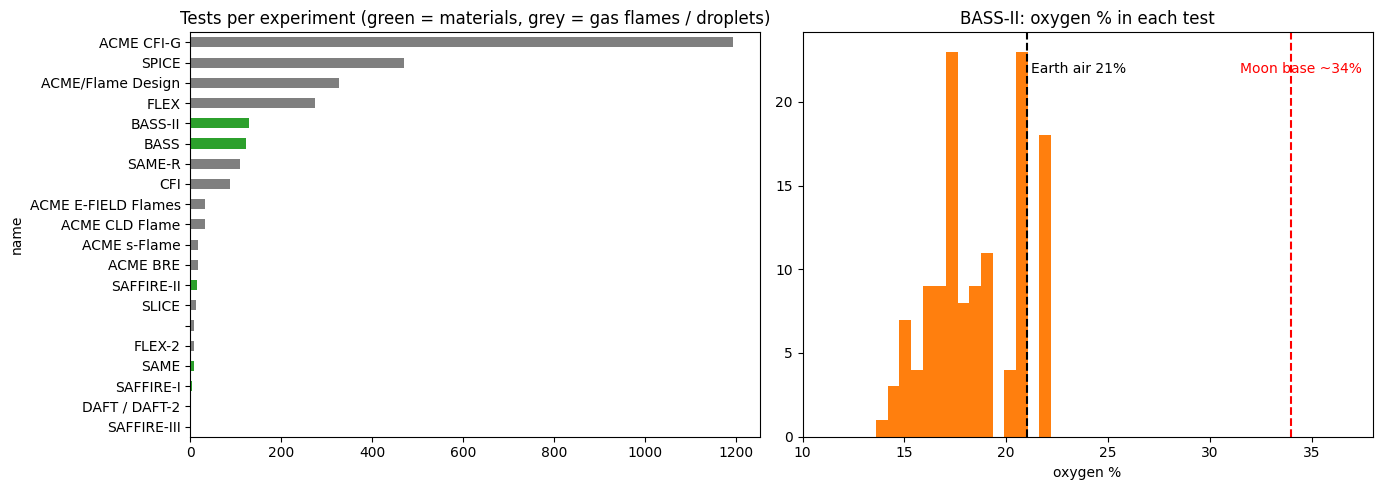

In [12]:
# Step 6: picture it. Left: how many tests each experiment ran. Right: the oxygen levels BASS-II tested.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
s = summary.set_index("name")["tests"].sort_values()
colors = ["tab:green" if n in ("BASS", "BASS-II", "SAFFIRE-I", "SAFFIRE-II", "SAFFIRE-III", "SAME") else "tab:gray" for n in s.index]
s.plot.barh(ax=ax[0], color=colors)
ax[0].set_title("Tests per experiment (green = materials, grey = gas flames / droplets)")
o2 = pd.to_numeric(bass2[[c for c in bass2.columns if "initial O2" in c][0]], errors="coerce").dropna()
ax[1].hist(o2, bins=15, color="tab:orange")
ax[1].axvline(21, color="k", ls="--"); ax[1].text(21.2, ax[1].get_ylim()[1]*0.9, "Earth air 21%")
ax[1].axvline(34, color="r", ls="--"); ax[1].text(31.5, ax[1].get_ylim()[1]*0.9, "Moon base ~34%", color="r")
ax[1].set_xlim(10, 38); ax[1].set_title("BASS-II: oxygen % in each test"); ax[1].set_xlabel("oxygen %")
plt.tight_layout(); plt.show()


## 7. Inside one experiment
The full record of BASS-II: goal, method, hypothesis, why it matters on Earth. Every experiment has these fields, and the **experiment cards** on our site are built from them.

In [13]:
# Step 7: the full record of one experiment (BASS-II). The experiment cards get their text from here.
rec = records["PSI-25"]
for field in ["title", "investigationAcronym", "investigationStartDate", "investigationEndDate",
              "experimentHardware", "objective", "approach", "hypothesis", "researchImpacts"]:
    print(f"--- {field}\n{rec.get(field, '')}\n")


--- title
Burning and Suppression of Solids - II

--- investigationAcronym
BASS-II

--- investigationStartDate
01-01-2010

--- investigationEndDate
12-31-2022

--- experimentHardware
Microgravity Science Glovebox (MSG)

--- objective
BASS-II results contribute to the combustion computational models used in the design of fire detection and suppression systems in microgravity and on Earth.
Objectives Include:
  1) Study the ignition, flame growth, flame spread, and extinction limits for solid fuels burning in low-velocity forced flows in microgravity.
  2) Begin to bridge the gap between the normal gravity NASA-STD-6001 Test #1 method, ground-based microgravity tests, and actual material flammability in microgravity.
  3) Provide SoFIE PIs with preliminary data to refine Science Requirements.
  4)  Practical, realistic (thicker) fuels in typical geometries will be examined, including slabs, cylinders, and spherical sections.

The primary variables include:
     • Forced flow velocity (sp

## 8. The papers: where the results are
352 papers are linked to these experiments. The tables say how each test was set up; what happened (how fast the flame spread, when it went out) is mostly in these papers.

In [14]:
# Step 8: the papers. The results (how fast it spread, when it went out) are mostly in here, not in the tables.
papers = pd.DataFrame([{"id": a, "name": inv.set_index("id").loc[a, "name"], "papers": len(r.get("publications", []))}
                       for a, r in records.items()]).sort_values("papers", ascending=False)
print(papers.papers.sum(), "papers in total\n")
print(papers.to_string(index=False), "\n")
print("BASS-II's papers:")
pd.DataFrame([{"title": p["title"], "authors": p["authorList"], "doi": p["doi"]}
              for p in records["PSI-25"]["publications"]])


352 papers in total

     id                name  papers
 PSI-69                FLEX      51
 PSI-68              FLEX-2      48
 PSI-23        ACME s-Flame      44
 PSI-10   ACME/Flame Design      33
 PSI-22 ACME E-FIELD Flames      25
 PSI-21      ACME CLD Flame      18
 PSI-25             BASS-II      17
PSI-102                SAME      16
 PSI-20            ACME BRE      16
PSI-142                          12
 PSI-26                BASS      10
PSI-117                          10
PSI-107               SPICE       9
 PSI-39                 CFI       7
 PSI-99          SAFFIRE-II       7
PSI-101              SAME-R       6
 PSI-98           SAFFIRE-I       6
PSI-106               SLICE       5
 PSI-62                           4
PSI-100         SAFFIRE-III       3
 PSI-47       DAFT / DAFT-2       2
PSI-159          ACME CFI-G       2
 PSI-60                           1
PSI-115                           0 

BASS-II's papers:


,title,authors,doi
0,Microgravity flammability boundary for PMMA ro...,"Olson Sandra L., Ferkul Paul V.",10.1016/j.combustflame.2017.03.001
1,Temperature and CO2 fields of a downward sprea...,"Bhattacharjee Subrata, Paolini Christopher, Tr...",10.1016/j.proci.2014.05.093
2,Opposed-flow flame spread: A comparison of mic...,"Bhattacharjee Subrata, Laue Matthew, Carmignan...",10.1016/j.firesaf.2015.11.011
3,The critical flow velocity for radiative extin...,"Bhattacharjee Subrata, Simsek Aslihan, Olson S...",10.1016/j.combustflame.2015.10.023
4,Experimental validation of a correlation captu...,"Bhattacharjee Subrata, Tran Wynn, Laue Matthew...",10.1016/j.proci.2014.06.125
5,Results from on-board CSA-CP and CDM Sensor Re...,"SL Olson, PV Ferkul, S Bhattacharjee, FJ Mille...",
6,Modeling and Analysis of Intermediate Thicknes...,"TJ Shah, FJ Miller, S Olson, I Wichman",
7,"Concurrent flame growth, spread and extinction...","X Zhao, JS Tien, PV Ferkul, S. Olson",
8,"Radiative, thermal, and kinetic regimes of opp...","Bhattacharjee Subrata, Simsek Aslihan, Miller ...",10.1016/j.proci.2016.06.025
9,"Concurrent flame growth, spread, and quenching...","Zhao Xiaoyang, Liao Ya-Ting T., Johnston Micha...",10.1016/j.proci.2016.06.028


## 9. The raw files: big, and we will not use most of them
Videos, sensor logs, images: about 13.5 TB. Listed here so nobody tries to download them.

In [15]:
# Step 9: the raw files: videos, sensor logs, images. Huge, so we list them, we do not download them.
import os
rows = []
for a, r in records.items():
    files = [f for f in r.get("added", []) if f.get("visible", True)]
    kinds = pd.Series([os.path.splitext(f["file_name"])[1].lower() for f in files]).value_counts()
    rows.append({"id": a, "name": inv.set_index("id").loc[a, "name"], "files": len(files),
                 "size GB": round(r.get("totalFileSize", 0) / 1e9, 1),
                 "main kinds": ", ".join(f"{k} {v}" for k, v in kinds.head(3).items())})
raw = pd.DataFrame(rows).sort_values("size GB", ascending=False)
print(f"{raw['size GB'].sum() / 1000:.1f} TB in {raw.files.sum()} files\n")
raw


13.5 TB in 16354 files



,id,name,files,size GB,main kinds
0,PSI-10,ACME/Flame Design,3807,2180.4,".zip 1184, .txt 993, .csv 636"
9,PSI-159,ACME CFI-G,3756,2085.6,".txt 1022, .zip 987, .csv 680"
10,PSI-20,ACME BRE,1,2035.6,.csv 1
11,PSI-21,ACME CLD Flame,1,2005.5,.csv 1
20,PSI-68,FLEX-2,0,1224.8,
12,PSI-22,ACME E-FIELD Flames,0,950.2,
21,PSI-69,FLEX,0,923.8,
13,PSI-23,ACME s-Flame,4163,782.2,".zip 2037, .txt 963, .csv 576"
16,PSI-39,CFI,2831,718.9,".txt 1793, .zip 338, .meta 236"
14,PSI-25,BASS-II,694,274.6,".mp4 296, .zip 265, .pdf 127"


## 10. One raw file up close
A small one (2.7 MB): the sensor log of Saffire-I, a real fire lit on a cargo spacecraft. It shows what raw data means: thousands of rows per test, one per moment.

RawData                     9749 rows x 48 columns: ['RelativeSeconds', 'CygnusTimestamp', 'SaffireTimestamp', 'Cyg-Saf TS (ms)', 'Radiometer1Value', 'Radiometer2Value']
CygnusData                  8072 rows x 23 columns: ['CygnusTimestamp', 'Relative Time (ms)', 'Relative Time (s)', 'PCM Air Temp (degC)', 'PCM Press (psi)', 'PCM Press/Temp (psi/K)']
CygnusSmokeDetectorData      290 rows x  9 columns: ['FIZ 2 Obscuration', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'FIZ 2 Scatter']
CygnusPressureData           332 rows x 10 columns: ['CygnusTimestamp', 'Relative Time (ms)', 'Relative Time (s)', 'PCM Press (psi)', 'Unnamed: 4', 'Unnamed: 5']
CygnusTemperatureData        322 rows x  4 columns: ['CygnusTimestamp', 'Relative Time (ms)', 'Relative Time (s)', 'PCM Air Temp (degC)']
SaffireData                 6083 rows x 33 columns: ['SaffireTimestamp', 'delta timestamp (ms)', 'Relative Time (ms)', 'Relative Time (s)', 'Radiometer1Value', 'Radiometer2Value']


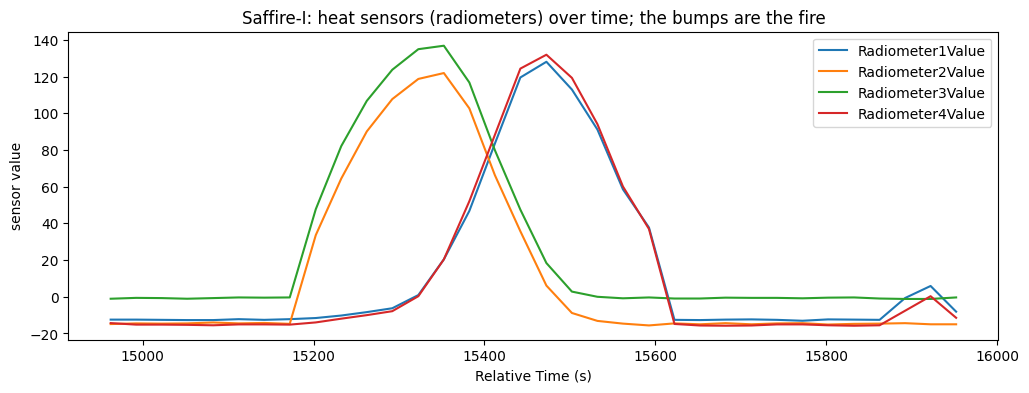

In [18]:
# Step 10: a peek at one small raw file: Saffire-I's sensor log (2.7 MB) from a real fire on a cargo spacecraft
x = pd.read_excel(io.BytesIO(download("PSI-98", "PSI-98_Raw Data_Saffire-I Telemetry Data Good Process Version.xlsx", 1)),
                  sheet_name=None)
for name, sheet in x.items():
    print(f"{name:26} {sheet.shape[0]:5} rows x {sheet.shape[1]:2} columns:", list(sheet.columns)[:6])
s = x["SaffireData"]
s = s[s["Radiometer1Value"] > -1000]   # before the sensors switch on, the log holds about -4000: not a reading
ax = s.plot(x="Relative Time (s)", y=[c for c in s.columns if c.startswith("Radiometer")], figsize=(12, 4),
            title="Saffire-I: heat sensors (radiometers) over time; the bumps are the fire")
ax.set_ylabel("sensor value"); plt.show()


## 11. The second tables
Two experiments have a second test table with other columns.

In [17]:
# Step 11: the second test tables of ACME Flame Design and ACME CFI-G (step 4 showed only the first)
for a, ts in all_tables.items():
    for i, t in enumerate(ts[1:], start=2):
        print(f"{a} {inv.set_index('id').loc[a, 'name']} table {i}: {len(t)} rows ->", list(t.columns)[:10])
        display(t.head(5))


PSI-10 ACME/Flame Design table 2: 120 rows -> ['Flame Type', 'Day', 'Test', 'XO2', 'mO2 (mg/s)', 'mN2 (mg/s)', 'mtot (mg/s)', 'XC2H4 initial', 'XC2H4 final', 'pinit (atm)']


,Flame Type,Day,Test,XO2,mO2 (mg/s),mN2 (mg/s),mtot (mg/s),XC2H4 initial,XC2H4 final,pinit (atm),pfinal (atm),pmean (atm),mean Zst,Tad (K)
0,Inverse,1,21328A1,0.37082819,5.116084436,7.599363286,12.71544772,0.271563,0.270263,0.998235,1.009803,1.004019,0.302316402,2595.073097
1,Inverse,1,21328A2,0.371286026,5.116388106,7.584919544,12.70130765,0.270263,0.269163,1.001637,1.013885,1.007761,0.30350118,2594.870605
2,Inverse,1,21328D1,0.212319452,2.367048277,7.687948069,10.05499635,0.269163,0.242856,1.003678,1.092819,1.048249,0.211548493,2192.217132
3,Inverse,1,21328N1,0.849977932,9.799337625,1.514213825,11.31355145,0.082213,0.081615,0.949242,0.960810,0.955026,0.755160549,2335.819318
4,Inverse,1,21328N2,0.849977932,7.987785467,1.234289056,9.222074523,0.081615,0.081199,0.950603,0.959449,0.955026,0.756306904,2330.954842


PSI-159 ACME CFI-G table 2: 1015 rows -> ['Flame Type', 'Day', 'Fuel', 'Test', 'Xf  before test', 'Xf  after test', 'approx p (bar)', 'XO2', 'HC burnrate (mg/s)', 'O2 flow rate (mg/s)']


,Flame Type,Day,Fuel,Test,Xf before test,Xf after test,approx p (bar),XO2,HC burnrate (mg/s),O2 flow rate (mg/s),TFP,Tad (K),Zst,Hot ignition,burn time (sec),Self -ext or flow term,Peak burner Temp (C),Peak burner temp (K),Color,Comments
0,Inverse,1.0,ethane,21196 A1,0.298100,0.298100,1.1000,0.210,1.5,5.590000,No,2120.000000,0.166500,No,0.0,-,27.1,300.25,-,Failed to ignite
1,Inverse,1.0,ethane,21196 A2,0.298100,0.295425,1.1000,0.210,1.5,5.590000,No,2120.000000,0.166500,Yes,35.0,FT,162.9,436.05,yellow,NaN
2,Inverse,1.0,ethane,21196 F1,0.295425,0.291765,1.1033,0.150,1.5,5.586754,No,1786.994366,0.126728,Yes,36.0,FT,118.5,391.65,blue,Not spherical shape
3,Inverse,1.0,ethane,21196 H1,0.291765,0.291765,1.1033,0.120,1.5,5.586754,No,1567.030825,0.105557,No,0.0,-,26.7,299.85,-,Not ignited
4,Inverse,1.0,ethane,21196 J1,0.291765,0.291654,1.1033,0.135,1.5,5.586754,No,1680.718299,0.116988,flash,1.0,SE,27.8,300.95,-,Not lasted long


## What is messy: the to-do list for the cleaning notebook

**Tables**
- Every experiment names its columns differently (`Material`, `Fuel Sample Material`, `Sample Material  ` with spaces).
- Typos in column names: Saffire-II has `Samle Thickness`.
- Units sit in the column name, in the value or nowhere (`0.27 mm`, `20 cm/s`, `Air Flow`).
- BASS-II gives airflow as a fan setting (`Fan display`, `Air display`), not cm/s. Its fan calibration file (Reference Data) converts it.
- BASS has no oxygen or airflow column at all: date, sample and material only.
- Oxygen is sometimes a range or approximate (`21.5 - 21.7`, `~ 21.5`) and sometimes not measured but derived (Saffire-II, Note 1).
- Footnotes are stored as rows: Saffire-II's last rows are `Note 1 ...` to `Note 4 ...`, not tests.
- Some rows are not tests (Saffire `pre-test flow visualization`).
- Materials are free text: `100 micron PMMA film 2 cm wide`, `2 cm 0.1 mm PMMA film`, `1/4" black rod`, `sibal` (cotton-fiberglass).
- Sample numbers carry letters (`153m`), so they are text, not numbers.
- Two experiments have a second table with different columns (step 11).

**Raw files**
- Sensor logs hold filler values (about -4000) before the sensors switch on, and Excel sheets have unnamed columns.

**What the tables do not hold**
- The result of most tests (spread rate, did it go out). It is in the papers (step 8) and the raw files (step 9).
- Any material test at a pressure other than normal cabin pressure, or above 22% oxygen.

**The goal of the cleaning notebook:** one table for the ~280 material tests with
`experiment, test, material, thickness, oxygen %, airflow cm/s, flow direction, pressure, result, source`.
